# [v3] NB3 — 모델 로드 + 검증 (재구성)
NB2가 업로드한 adapter/GGUF를 로드해 평가만 수행. **EXPERIMENT_STAGE**로 NB01-04/NB02와 정합.

| Section | 내용 |
|---|---|
| **1. 모델 로드 + 통합 평가 (정본)** | Block 0(P1~P5 우선순위 평가) · KV bench · Block 1/1F(데이터셋 검증) · Step 0 · F7-NB03 — 구버전 중복 셀(즉시생성 30개/DEBUG/legacy 평가 루프) 제거, Block 0으로 일원화 |
| **2. LLM-as-Judge** | judge.py 단일 소스 — 자유출력 2-key(`what_missing`/`reasoning`)만 채점, teacher 백엔드 + 신뢰성 검증 3종 |
| **2.5 Visualization** | Fig 1 Rejection funnel(Sankey) · Fig 2 Calibration(라벨 함수 vs student) · Fig 3 다양성 산점 — NB 내 구현 가능분 (GKE full-pipeline 필요분 제외) |
| **3. Fraudecom Data Intuition** | 구 NB01의 데이터 자체 실험을 NB01-04 변수로 통합 정리 — 신호 AUROC / boundary spread / fusion 천장 / reroute 재정렬 진단 |

## Section 0: 환경

In [1]:
# GCP 인증 — gcsfuse 마운트를 위해 여전히 필요
# (Groq API는 별도 API key로 동작, GCP 인증과 무관)
from google.colab import auth
auth.authenticate_user()
print('✅ GCP 인증 완료 (gcsfuse 마운트용)')

✅ GCP 인증 완료 (gcsfuse 마운트용)


In [2]:
# 2. gcsfuse 설치
!echo "deb http://packages.cloud.google.com/apt gcsfuse-`lsb_release -c -s` main" | sudo tee /etc/apt/sources.list.d/gcsfuse.list
!curl https://packages.cloud.google.com/apt/doc/apt-key.gpg | sudo apt-key add -
!sudo apt-get update
!sudo apt-get install gcsfuse

deb http://packages.cloud.google.com/apt gcsfuse-jammy main
  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
  0     0    0     0    0     0      0      0 --:--:-- --:--:-- --:--:--     0Warning: apt-key is deprecated. Manage keyring files in trusted.gpg.d instead (see apt-key(8)).
100  1022  100  1022    0     0  12732      0 --:--:-- --:--:-- --:--:-- 12775
OK
Hit:1 https://cli.github.com/packages stable InRelease
Hit:2 http://packages.cloud.google.com/apt gcsfuse-jammy InRelease
Get:3 https://cloud.r-project.org/bin/linux/ubuntu jammy-cran40/ InRelease [3,632 B]
Hit:4 http://security.ubuntu.com/ubuntu jammy-security InRelease
Hit:5 http://archive.ubuntu.com/ubuntu jammy InRelease
Hit:6 http://archive.ubuntu.com/ubuntu jammy-updates InRelease
Hit:7 http://archive.ubuntu.com/ubuntu jammy-backports InRelease
Hit:8 https://r2u.stat.illinois.edu/ubuntu jammy InRelease
Hit:9 https:

In [3]:
# gcsfuse 설치 & 버킷 마운트
import os

GCS_BUCKET  = "fraud_ecomm"
GCP_PROJECT = "kakaoo-501107"
MOUNT_POINT = "/content/gcs_mount"

!apt-get install -y -q gcsfuse

os.makedirs(MOUNT_POINT, exist_ok=True)

# gcsfuse 마운트 (ADC 자격증명 자동 사용)
!gcsfuse --implicit-dirs \
    --key-file="" \
    {GCS_BUCKET} {MOUNT_POINT} 2>&1 | tail -3

# 마운트 확인
result = os.listdir(MOUNT_POINT)
print(f'✅ GCS 마운트 완료: {MOUNT_POINT}')
print(f'   최상위 폴더: {result[:5]}')

Reading package lists...
Building dependency tree...
Reading state information...
gcsfuse is already the newest version (3.11.1).
0 upgraded, 0 newly installed, 0 to remove and 161 not upgraded.
{"timestamp":{"seconds":1784744562,"nanos":277008204},"severity":"INFO","message":"GCSFuse Config","mount-id":"fraud_ecomm-2aed934c","CLI Flags":{"implicit-dirs":"true","key-file":""}}
{"timestamp":{"seconds":1784744562,"nanos":277028372},"severity":"INFO","message":"GCSFuse Config","mount-id":"fraud_ecomm-2aed934c","Full Config":{"AppName":"","CacheDir":"","CloudProfiler":{"AllocatedHeap":true,"Cpu":true,"Enabled":false,"Goroutines":false,"Heap":true,"Label":"gcsfuse-0.0.0","Mutex":false,"ServiceName":"gcsfuse"},"Debug":{"ExitOnInvariantViolation":false,"Fuse":false,"Gcs":false,"LogMutex":false},"DisableAutoconfig":false,"DummyIo":{"Enable":false,"PerMbLatency":0,"ReaderLatency":0},"EnableAtomicRenameObject":true,"EnableGoogleLibAuth":true,"EnableHns":true,"EnableNewReader":true,"EnableStandar

In [4]:
# v5: 공통 패키지 일괄 설치 (provider 무관)
!pip install -q \
    trl peft transformers accelerate datasets \
    groq google-genai \
    bitsandbytes

# !pip install flash-attn --no-build-isolation -q #flash attention 일단 제거
# google-generativeai
print("✅ 설치 완료")

✅ 설치 완료


In [5]:
# [1] 패키지 (--no-deps로 환경 보호)
!pip install -q llama-cpp-python --no-deps
!pip install -q diskcache gguf

## Bootstrap: 공통 모듈 + 데이터 로드

In [6]:
# ============================================================
# 공통 모듈(common/*.py) 로드 — 버킷에서 로컬로 복사 후 import
# (편집-반영 안정 + import 캐시 회피). 버킷 경로는 환경에 맞게 1회 수정.
# ============================================================
import sys, os, shutil, importlib

COMMON_SRC = "/content/gcs_mount/tree-search/analyzer_ft/common"   # ← .py 업로드 위치
COMMON_DST = "/content/common"
shutil.rmtree(COMMON_DST, ignore_errors=True)
shutil.copytree(COMMON_SRC, COMMON_DST)
if COMMON_DST not in sys.path:
    sys.path.insert(0, COMMON_DST)

import config, prompts, data_io, schema
for _m in (config, prompts, data_io, schema):
    importlib.reload(_m)
print("✅ common 모듈 로드:", [m.__name__ for m in (config, prompts, data_io, schema)])


✅ common 모듈 로드: ['config', 'prompts', 'data_io', 'schema']


In [7]:
# ============================================================
# 데이터 로드 + 런타임 바인딩 — EXPERIMENT_STAGE 정합 (NB01-04/NB02 v3와 동일 스위치)
# ============================================================
from config import *
PHASE = "train"

# ════════ EXPERIMENT_STAGE ════════
EXPERIMENT_STAGE = "S4"     # ★ "S1" | "S2" | "S3" | "S4"
_STAGE_CFG = {
    "S1": dict(mode="forward", train_mode="forward_full", use_grpo=False, stem="training_data_forward_s1"),
    "S2": dict(mode="forward", train_mode="forward_full", use_grpo=False, stem="training_data_forward"),
    "S3": dict(mode="agent",   train_mode="wm_focus",     use_grpo=False, stem="training_data_mined_3key"),
    "S4": dict(mode="agent",   train_mode="wm_only",      use_grpo=True,  stem="training_data_mined"),
}[EXPERIMENT_STAGE]
mode       = _STAGE_CFG["mode"]
TRAIN_MODE = _STAGE_CFG["train_mode"]
USE_GRPO   = _STAGE_CFG["use_grpo"]          # 평가 대상 어댑터 선택 (수동 override 가능)
USE_GGUF   = True   # ← True: GGUF CPU 추론(서빙 동일) / False: SFT adapter(GPU)

config.ensure_dirs()
config.print_config()
globals().update(config.set_data(mode=mode))

# ── ★ STAGE stem으로 jsonl 유일 경로 확정 (stale 후보 로직 제거 — NB02 v3와 동일 원칙) ──
import os as _os
_base_dir = _os.path.dirname(TRAINING_JSONL_PATH)
TRAINING_JSONL_PATH = _os.path.join(_base_dir, f"{_STAGE_CFG['stem']}.jsonl")
EVAL_JSONL_PATH     = _os.path.join(_base_dir, f"{_STAGE_CFG['stem']}_eval.jsonl")
print(f"■ EXPERIMENT_STAGE={EXPERIMENT_STAGE}  mode={mode}  TRAIN_MODE={TRAIN_MODE}")
print(f"■ train: {TRAINING_JSONL_PATH}\n■ eval : {EVAL_JSONL_PATH}")

globals().update(data_io.load_all(mode=mode))

# 어댑터 GCS 경로 — NB02(v3) 저장 규칙과 일치 (S1/S3은 stage 접미)
METHOD_SUFFIX = "grpo" if USE_GRPO else "sft"
MODEL_TAG = f"{mode}_" if EXPERIMENT_STAGE in ("S2", "S4") else f"{mode}_{EXPERIMENT_STAGE.lower()}_"
ADAPTER_GCS   = f"{os.path.dirname(OUT_ADAPTER_PATH.rstrip('/'))}/{MODEL_TAG}adapter_{METHOD_SUFFIX}"
BASE_MODEL_ID = "Qwen/Qwen2.5-0.5B-Instruct"
GEN_MAX_NEW = {"cls": 32, "wm_focus": 40, "wm_only": 32, "forward_full": 56}.get(TRAIN_MODE, 64)

from prompts import (SYSTEM_PROMPT, build_sample, extract_test_features,
                     build_analyzer_user_prompt, build_teacher_prompt_with_gt,
                     compute_l2_distances, format_top5_neighbors,
                     format_transaction, format_persona, normalize_dist, dist_tag,
                     NUMERIC_COLS, CATEGORICAL_COLS)
print("✅ 런타임 준비 완료")

PHASE            : generate
EXPERIMENT_CASE  : pca_64_k100
TEACHER_PROVIDER : huggingface
TEACHER_MODEL    : Qwen/Qwen2.5-14B-Instruct
GENERATION_MODE  : mining_only
TRAIN_ON         : mining_only
TRAINING_JSONL   : 
OUT_ADAPTER_PATH : /content/gcs_mount/tree-search/analyzer_ft/pca_64_k100/hf_0713/adapter
■ EXPERIMENT_STAGE=S4  mode=agent  TRAIN_MODE=wm_only
■ train: /content/gcs_mount/tree-search/analyzer_ft/pca_64_k100/hf_0713/training_data_mined.jsonl
■ eval : /content/gcs_mount/tree-search/analyzer_ft/pca_64_k100/hf_0713/training_data_mined_eval.jsonl
✅ data_io.load_all(mode=agent)
   personas=100  coreset_map=122,810
   test=28,302  normal/abnormal=14151/14151
   dist p25/p50/p75=1.264/1.448/1.651  IQR=0.387
✅ 런타임 준비 완료


## Section 1 — 모델 로드 + 통합 평가 (정본)
Block 0이 추론 평가의 유일한 정본. 구버전의 즉시생성 30개·DEBUG raw 출력·legacy 평가 루프·
심화 factual-grounding 셀은 Block 0의 P1~P5와 중복이므로 제거됨.

In [8]:
!pip uninstall -y -q torchao

In [9]:
# ============================================================
# 학습된 LoRA adapter 로드 (NB2가 GCS에 업로드한 것)
# 결과 변수: student_model / student_tokenizer  (eval 셀과 호환)
# ============================================================
# ============================================================
# 모델 로드: SFT adapter vs GGUF(CPU) — flag로 전환
#   USE_GGUF=False → 기존 PeftModel (GPU)
#   USE_GGUF=True  → llama-cpp-python (CPU 서빙과 동일)
# ============================================================
import torch, shutil, os
from transformers import AutoModelForCausalLM, AutoTokenizer

student_tokenizer = AutoTokenizer.from_pretrained(BASE_MODEL_ID)
if student_tokenizer.pad_token is None:
    student_tokenizer.pad_token = student_tokenizer.eos_token

if not USE_GGUF:
    # ── 기존 경로: SFT adapter (GPU) ──
    from peft import PeftModel
    ADAPTER_LOCAL = f"/content/eval_adapter_{METHOD_SUFFIX}"
    shutil.rmtree(ADAPTER_LOCAL, ignore_errors=True)
    shutil.copytree(ADAPTER_GCS, ADAPTER_LOCAL)
    _base = AutoModelForCausalLM.from_pretrained(
        BASE_MODEL_ID, torch_dtype=torch.float32, device_map="auto")
    student_model = PeftModel.from_pretrained(_base, ADAPTER_LOCAL)
    student_model.eval()
    print(f"✅ SFT adapter 로드 (GPU): {ADAPTER_GCS}")
else:
    # ── GGUF 경로: llama-cpp-python (CPU, GKE 서빙과 동일) ──
    !pip install -q llama-cpp-python --no-deps
    !pip install -q diskcache
    from llama_cpp import Llama
    GGUF_GCS   = f"{ADAPTER_GCS}/gguf/model_q4.gguf"
    GGUF_LOCAL = f"/content/eval_{METHOD_SUFFIX}_q4.gguf"
    !gsutil cp {GGUF_GCS} {GGUF_LOCAL}
    _llm = Llama(model_path=GGUF_LOCAL, n_ctx=2048, n_threads=4, verbose=False)
    student_model = None   # GGUF는 _llm 사용
    print(f"✅ GGUF Q4 로드 (CPU): {GGUF_GCS}")


# ── 통일 추론 함수: 평가 루프는 이것만 호출 (flag 무관) ──
def student_infer(system: str, user: str, max_new_tokens: int = 96) -> str:
    """SFT/GGUF 둘 다 동일 인터페이스로 텍스트(assistant) 반환."""
    if USE_GGUF:
        prompt = (f"<|im_start|>system\n{system}<|im_end|>\n"
                  f"<|im_start|>user\n{user}<|im_end|>\n<|im_start|>assistant\n")
        out = _llm(prompt, max_tokens=GEN_MAX_NEW, temperature=0.0,
                   stop=["<|im_end|>"])
        return out["choices"][0]["text"]
    else:
        prompt = student_tokenizer.apply_chat_template(
            [{"role":"system","content":system},{"role":"user","content":user}],
            tokenize=False, add_generation_prompt=True)
        inputs = student_tokenizer(prompt, return_tensors="pt",
                                   add_special_tokens=False).to(student_model.device)
        with torch.no_grad():
            out = student_model.generate(
                **inputs, max_new_tokens=GEN_MAX_NEW, do_sample=False,
                pad_token_id=student_tokenizer.pad_token_id,
                eos_token_id=student_tokenizer.eos_token_id)
        return student_tokenizer.decode(out[0][inputs['input_ids'].shape[1]:],
                                        skip_special_tokens=True)

Google recommends using Gcloud storage CLI (https://docs.cloud.google.com/storage/docs/discover-object-storage-gcloud) instead of gsutil. Please refer to migration guide (https://docs.cloud.google.com/storage/docs/gsutil-transition-to-gcloud) for assistance.
Copying file:///content/gcs_mount/tree-search/analyzer_ft/pca_64_k100/hf_0713/agent_adapter_grpo/gguf/model_q4.gguf...
-
Operation completed over 1 objects/379.4 MiB.                                    
✅ GGUF Q4 로드 (CPU): /content/gcs_mount/tree-search/analyzer_ft/pca_64_k100/hf_0713/agent_adapter_grpo/gguf/model_q4.gguf


In [10]:
# ── 학습/평가 jsonl 로드 — STAGE 단일 경로 (train-split fallback 금지) ──
import json, os

def _load_jsonl(path):
    recs = [json.loads(l) for l in open(path, encoding="utf-8") if l.strip()]
    print(f"  📂 로드: {path}  ({len(recs)}개)")
    return recs

training_records = _load_jsonl(TRAINING_JSONL_PATH)
if not os.path.exists(EVAL_JSONL_PATH):
    raise FileNotFoundError(
        f"eval jsonl 없음: {EVAL_JSONL_PATH}\n"
        f"→ NB01-04(v3) F3-c를 동일 EXPERIMENT_STAGE={EXPERIMENT_STAGE}로 실행해 생성"
        " (eval은 train split이 아니라 test set 후미 구간의 별도 추론 패스가 원칙)")
eval_recs = _load_jsonl(EVAL_JSONL_PATH)
print(f"   NORMAL={sum(r['metadata']['gt_label']==0 for r in eval_recs)}  "
      f"ABNORMAL={sum(r['metadata']['gt_label']==1 for r in eval_recs)}")

  📂 로드: /content/gcs_mount/tree-search/analyzer_ft/pca_64_k100/hf_0713/training_data_mined.jsonl  (1844개)
  📂 로드: /content/gcs_mount/tree-search/analyzer_ft/pca_64_k100/hf_0713/training_data_mined_eval.jsonl  (300개)
   NORMAL=150  ABNORMAL=150


In [11]:
# NB03에서 GGUF/adapter 경로 출력
print("ADAPTER_GCS:", ADAPTER_GCS)
print("GGUF_GCS:", GGUF_GCS if USE_GGUF else "N/A")
print("DATE:", DATE)
# 학습 데이터 첫 줄의 assistant 키 확인
import json
rec = json.loads(open(OUT_JSONL_MINED).readline())
print("학습 데이터 assistant 키:", list(json.loads(rec['assistant']).keys()))

ADAPTER_GCS: /content/gcs_mount/tree-search/analyzer_ft/pca_64_k100/hf_0713/agent_adapter_grpo
GGUF_GCS: /content/gcs_mount/tree-search/analyzer_ft/pca_64_k100/hf_0713/agent_adapter_grpo/gguf/model_q4.gguf
DATE: 0713
학습 데이터 assistant 키: ['cls', 'sufficiency', 'what_missing']


## ★ Block 0 — 우선순위 평가 (agent/forward 공용 정본)
mode 스위치 하나로 wm(agent)/reasoning(forward)을 같은 지표로 평가. P1 grounded-consistency(사실 정합)가 최우선 — **인용율만으로는 의도대로 작동한다고 판단할 수 없음**(정합 서술도 인용율을 통과)이 확인된 교훈의 반영. 아래 Section 11/12의 구버전 평가 셀들은 legacy 표기 — 참고용으로만 유지.

In [12]:
# ============================================================
# ★ Block 0 — 우선순위 평가 (agent/forward 공용, 이 셀이 정본)
# ------------------------------------------------------------
# EVAL_TARGET은 bootstrap의 mode를 따름 ("agent"→wm, "forward"→reasoning).
# 우선순위 (프로젝트 의도 기준):
#  P1 grounded-consistency — 인용 feature가 "실제로" deviant/ok인지 사실 정합
#     (※ 인용율만 보면 정합 서술도 통과 — NB04 초기 평가의 오판 교정)
#  P2 teacher-parity      — teacher 상한 대비 인용 feature Jaccard/방향 일치
#  P3 [agent] wm 형식 준수율("<direction>: <evidence>") + direction 분포
#     [forward] confidence ECE (cls-GT 일치 기준)
#  P4 다양성 — 고유율 / top1 / soft-top1(정규화 40자 키)
#  P5 cls acc/FNR (det 모드 서빙에선 참고 지표 — nd threshold가 결정)
# 아래 legacy 셀들(Section 11/12 구버전)은 이 블록으로 대체됨.
# ============================================================
import json, re
import numpy as np
from collections import Counter

# EVAL_TARGET = mode if "mode" in dir() else "agent"     # "agent" | "forward"
EVAL_TARGET = mode
_TEXT_KEY   = "what_missing" if EVAL_TARGET == "agent" else "reasoning"
_FEATURE_PAT = re.compile(
    r"purchase_value|age|sex|source|browser|ip_country|weekday|month", re.I)
_DIR_PAT = re.compile(r"^(cluster_mismatch|neighbor_insufficient)\s*:")

def _feats(text):  return set(m.lower() for m in _FEATURE_PAT.findall(text or ""))
def _softkey(t):   return re.sub(r"[^a-z0-9 ]", "", (t or "").lower())[:40]

def _dev_table(rec):
    """metadata.test_idx → deviation dict 재구성 (persona 가용 시)."""
    try:
        idx = rec["metadata"].get("test_idx")
        cid = rec["metadata"].get("cluster_id", rec["metadata"].get("cluster_id"))
        persona = CLUSTER_PERSONAS.get(int(cid)) if cid is not None else None
        tf = extract_test_features(int(idx)) if idx is not None else None
        if not persona or tf is None:
            return None
        dev, ok = set(), set()
        for col, st in (persona.get("numeric_stats") or {}).items():
            v = tf.get(col)
            if v is None: continue
            z = (float(v) - float(st.get("mean", 0))) / (float(st.get("std", 0)) or 1e-6)
            (dev if abs(z) >= 1.0 else ok).add(col.lower())
        return {"deviant": dev, "ok": ok, "tf": tf}
    except Exception:
        return None

def run_priority_eval(records, infer_fn, n=100, seed=42):
    rng = np.random.default_rng(seed)
    sel = list(rng.choice(len(records), min(n, len(records)), replace=False))
    rows = []
    for i in sel:
        rec = records[int(i)]
        user = rec["user"]
        if EVAL_TARGET == "agent":                      # 서빙 정합: 주입 재현
            nd = rec["metadata"].get("top1_l2_dist_norm", -1)
            suf = "ambiguous" if 0.3 <= nd < 0.55 else "confident"
            if "retrieval_sufficiency =" not in user:   # ★ 이중 주입 방지 (NB01-04가 이미 주입)
                user = user + f"\n\n[SYSTEM-COMPUTED] retrieval_sufficiency = {suf.upper()}"
        try:
            out = infer_fn(rec["system"], user)
            d = json.loads(out[out.find("{"): out.rfind("}") + 1])
        except Exception:
            rows.append({"rec": rec, "parse_ok": False}); continue
        if len(rows) < 3:
            print("  raw:", repr(out[:200]))
            print("  parsed keys:", list(d.keys()), "| _TEXT_KEY:", _TEXT_KEY)
        rows.append({"rec": rec, "parse_ok": True,
                     "cls": str(d.get("cls", "")).upper(),
                     "text": d.get(_TEXT_KEY) or "",
                     "conf": d.get("confidence")})
    ok_rows = [r for r in rows if r["parse_ok"]]
    print(f"=== Block 0 우선순위 평가 [{EVAL_TARGET}] n={len(rows)} "
          f"(parse 성공 {len(ok_rows)}) ===")

    # ── P1. grounded-consistency ────────────────────────────
    g_n = g_ok = 0
    for r in ok_rows:
        if not r["text"] or r["text"] == "null": continue
        dev = _dev_table(r["rec"])
        if dev is None: continue
        cited = _feats(r["text"]) & (dev["deviant"] | dev["ok"])
        if not cited: continue
        g_n += 1
        if r["cls"] == "ABNORMAL":
            g_ok += int(bool(cited & dev["deviant"]))
        else:
            g_ok += int(bool(cited & dev["ok"]))
    print(f"[P1] grounded-consistency: {g_ok}/{g_n} = "
          f"{g_ok/max(g_n,1):.1%}  (인용 feature의 사실 정합)")

    # ── P2. teacher-parity ──────────────────────────────────
    jac, dmatch, tp_n = [], 0, 0
    for r in ok_rows:
        try:
            t = json.loads(r["rec"]["assistant"]).get(_TEXT_KEY) or ""
        except Exception:
            continue
        if not t or not r["text"]: continue
        fs, ft = _feats(r["text"]), _feats(t)
        if not ft: continue
        tp_n += 1
        jac.append(len(fs & ft) / max(len(fs | ft), 1))
        dmatch += int(bool(_DIR_PAT.match(r["text"])) == bool(_DIR_PAT.match(t)))
    print(f"[P2] teacher-parity: n={tp_n}  feature-Jaccard="
          f"{np.mean(jac) if jac else 0:.3f}  direction일치={dmatch/max(tp_n,1):.1%}")

    # ── P3. 모드별 핵심 축 ──────────────────────────────────
    if EVAL_TARGET == "agent":
        _mt = lambda r: (r["rec"]["metadata"].get("_mining_type")
                            or r["rec"]["metadata"].get("_mining_type", "")).replace("eval_", "")
        _g = [r for r in ok_rows if _mt(r) in ("type1_misrouted", "type2_cross_cluster")]
        for _dir, _gt in [("cluster_mismatch", "type1_misrouted"),
                          ("neighbor_insufficient", "type2_cross_cluster")]:
            yp = [r["text"].startswith(_dir) for r in _g]
            yt = [_mt(r) == _gt for r in _g]
            tp = sum(a and b for a, b in zip(yt, yp)); fp = sum((not a) and b for a, b in zip(yt, yp))
            fn = sum(a and (not b) for a, b in zip(yt, yp))
            print(f"[P3] {_dir:22s} P={tp/max(tp+fp,1):.3f} R={tp/max(tp+fn,1):.3f} "
                  f"(n={len(_g)}, GT율={sum(yt)/max(len(yt),1):.1%})")
    else:
        confs = np.array([r["conf"] for r in ok_rows if r["conf"] is not None], float)
        hits  = np.array([int(r["cls"] == ("ABNORMAL" if r["rec"]["metadata"]["gt_label"] else "NORMAL"))
                          for r in ok_rows if r["conf"] is not None], float)
        if len(confs) >= 10:
            bins = np.quantile(confs, np.linspace(0, 1, 6)); bins[-1] += 1
            ece = sum(((confs >= bins[b]) & (confs < bins[b+1])).mean()
                      * abs(hits[(confs >= bins[b]) & (confs < bins[b+1])].mean()
                            - confs[(confs >= bins[b]) & (confs < bins[b+1])].mean()/100)
                      for b in range(5) if ((confs >= bins[b]) & (confs < bins[b+1])).any())
            print(f"[P3] confidence ECE = {ece:.3f}  "
                  f"(mean conf {confs.mean():.1f}, std {confs.std():.1f})")

    # ── P4. 다양성 ──────────────────────────────────────────
    texts = [r["text"].strip().lower() for r in ok_rows if r["text"] and r["text"] != "null"]
    c, ck = Counter(texts), Counter(_softkey(t) for t in texts)
    if texts:
        print(f"[P4] 다양성: 고유율={len(c)/len(texts):.1%}  "
              f"top1={c.most_common(1)[0][1]/len(texts):.1%}  "
              f"soft-top1={ck.most_common(1)[0][1]/len(texts):.1%}")
        print(f"     최빈 3: {[(t[:48], k) for t, k in c.most_common(3)]}")

    # ── P5. cls (det 서빙에선 참고) ─────────────────────────
    if any(r["cls"] in ("NORMAL", "ABNORMAL") for r in ok_rows):
        y  = [int(r["rec"]["metadata"]["gt_label"]) for r in ok_rows]
        yp = [int(r["cls"] == "ABNORMAL") for r in ok_rows]
        tp = sum(a and b for a, b in zip(y, yp)); fn = sum(a and not b for a, b in zip(y, yp))
        print(f"[P5] cls acc={np.mean([a==b for a,b in zip(y,yp)]):.3f}  "
              f"FNR={fn/max(tp+fn,1):.3f}   (det 모드 서빙은 nd-threshold가 결정 — 참고 지표)")
    else:
        print("[P5] 1-key 모드 — cls는 코드(nd threshold)가 결정 → 모델 평가 대상 아님")
    return rows

# 사용 (모델 로드 + eval_recs 로드 후):
# _ = run_priority_eval(eval_recs, lambda s, u: _infer(s, u, max_new=GEN_MAX_NEW if "GEN_MAX_NEW" in dir() else 64), n=100)
# ★ 결과 보존 — Section 2(judge) / 2.5(Fig 2·3)가 재추론 없이 재사용
block0_rows = run_priority_eval(eval_recs, lambda s, u: student_infer(s, u), n=100)
_ = block0_rows

  raw: '{"what_missing": null}'
  parsed keys: ['what_missing'] | _TEXT_KEY: what_missing
  raw: '{"what_missing": null}'
  parsed keys: ['what_missing'] | _TEXT_KEY: what_missing
  raw: '{"what_missing": null}'
  parsed keys: ['what_missing'] | _TEXT_KEY: what_missing
=== Block 0 우선순위 평가 [agent] n=100 (parse 성공 72) ===
[P1] grounded-consistency: 2/13 = 15.4%  (인용 feature의 사실 정합)
[P2] teacher-parity: n=17  feature-Jaccard=0.569  direction일치=94.1%
[P3] cluster_mismatch       P=0.000 R=0.000 (n=0, GT율=0.0%)
[P3] neighbor_insufficient  P=0.000 R=0.000 (n=0, GT율=0.0%)
[P4] 다양성: 고유율=100.0%  top1=5.9%  soft-top1=5.9%
     최빈 3: [('neighbor_insufficient: ip_country, month_purchas', 1), ('cluster_mismatch: age z=-0.24 neighbor_spread=0.', 1), ('cluster_mismatch: age z=-1.24 diff -1.24 neighbo', 1)]
[P5] 1-key 모드 — cls는 코드(nd threshold)가 결정 → 모델 평가 대상 아님


In [13]:
if mode == "agent":
    print(eval_recs[0]["user"].count("retrieval_sufficiency ="))   # 1이어야 정상 (0=미주입, 2=이중주입)
else:
    print("⏭ forward — sufficiency 주입 없음")

1


In [14]:
# ── [Block0 마지막] KV prefix-cache latency 벤치 (GGUF/CPU 경로 전용) ──
def bench_kv_cache(n_list=(5,10,20), max_new=64):
    import time, numpy as np
    from llama_cpp import LlamaRAMCache
    assert "‌_llm" not in dir() and globals().get("_llm") is not None, "GGUF(_llm) 로드 후 실행"
    assert "eval_recs" in globals() and eval_recs, "eval_recs 필요"
    def _one(rec):
        prompt=(f"<|im_start|>system\n{rec['system']}<|im_end|>\n"
                f"<|im_start|>user\n{rec['user']}<|im_end|>\n<|im_start|>assistant\n")
        t0=time.time(); _llm(prompt, max_tokens=max_new, temperature=0.0, stop=["<|im_end|>"])
        return (time.time()-t0)*1000
    for N in n_list:
        recs=eval_recs[:min(N,len(eval_recs))]
        _llm.set_cache(None); _ = _one(recs[0])                       # OFF: 캐시 제거 + 워밍
        off=[_one(r) for r in recs]
        _llm.set_cache(LlamaRAMCache(capacity_bytes=256*1024*1024))   # ON
        _ = _one(recs[0])                                             # 정적 prefix를 캐시에 적재
        on=[_one(r) for r in recs]
        print(f"N={N:3d} | OFF mean={np.mean(off):6.0f}ms med={np.median(off):6.0f} "
              f"| ON mean={np.mean(on):6.0f}ms med={np.median(on):6.0f} "
              f"| Δmed={np.median(off)-np.median(on):+.0f}ms ({(1-np.median(on)/np.median(off))*100:+.0f}%)")

if USE_GGUF==True:
  # bench_kv_cache((5,10,EVAL_MAX_NUM),max_new=GEN_MAX_NEW)
  bench_kv_cache((5,10,10),max_new=GEN_MAX_NEW)

N=  5 | OFF mean=  2684ms med=  2670 | ON mean=  3211ms med=  3453 | Δmed=-783ms (-29%)
N= 10 | OFF mean=  1282ms med=  1318 | ON mean=  1400ms med=  1453 | Δmed=-135ms (-10%)
N= 10 | OFF mean=  1644ms med=  1330 | ON mean=  2451ms med=  1524 | Δmed=-194ms (-15%)


### 학습/평가 데이터셋 검증 (추론 없음)
Block 1(agent) / Block 1F(forward) — mode에 따라 해당 블록만 실행.

In [15]:
# ============================================================
# ★ Block 1 — 학습 데이터셋 검증 (direction 균형 · categorical grounding · cls-wm 정합)
#   위치: Block 0(cell 17) 뒤. 추론 없이 training_records의 assistant target을 직접 검사.
#   재사용: _dev_table / _DIR_PAT / EVAL_TARGET / _TEXT_KEY / CLUSTER_PERSONAS / extract_test_features
# ============================================================
EVAL_TARGET = EVAL_TARGET if "EVAL_TARGET" in dir() else mode
_TEXT_KEY   = _TEXT_KEY   if "_TEXT_KEY"   in dir() else ("what_missing" if EVAL_TARGET=="agent" else "reasoning")

def _dev_full(rec):
    """Block 0의 _dev_table(numeric)을 재사용하고 categorical 이탈까지 확장."""
    base = _dev_table(rec)
    if base is None: return None
    dev, ok, cat = set(base["deviant"]), set(base["ok"]), set()
    md = rec["metadata"]; cid = md.get("gt_cluster_id", md.get("cluster_id"))
    persona = CLUSTER_PERSONAS.get(int(cid)) if cid is not None else None
    for col, dist in ((persona or {}).get("categorical_distribution") or {}).items():
        v = base["tf"].get(col)
        if v is None: continue
        cl = col.lower(); cat.add(cl)
        tops = set(map(str, (dist.get("top_values") or dist.get("values") or list(dist)[:3] or [])))
        (ok if str(v) in tops else dev).add(cl)          # profile에 있으면 ok, 없으면 deviant
    return {"deviant": dev, "ok": ok, "cat": cat}

def _cited(text, dev):
    t = (text or "").lower()
    return {c for c in (dev["deviant"] | dev["ok"]) if c in t}   # full 컬럼명이 인용됐나

def validate_dataset(records, tag="train"):
    P = []
    for r in records:
        try: P.append((r, json.loads(r["assistant"])))
        except Exception: pass
    n = len(P)
    print(f"=== Block 1 데이터셋 검증 [{EVAL_TARGET}] {tag} n={n} ===")

    # (1) direction 균형 — agent 전용
    if EVAL_TARGET == "agent":
        d = Counter()
        for _, a in P:
            wm = a.get("what_missing"); m = _DIR_PAT.match(wm) if wm else None
            d[m.group(1) if m else ("null" if not wm else "other")] += 1
        cm, ni = d.get("cluster_mismatch", 0), d.get("neighbor_insufficient", 0)
        print(f"[1] direction 균형: {dict(d)}  (cm:ni = {cm/max(ni,1):.1f}:1)")
        print(f"    ▸ 목표 5:5~6:4. 한쪽>85%면 degenerate → 재생성 시 신호별 결합 필요")

    # (2) grounding 정합 (numeric+categorical) — Block 0가 못 본 categorical 포함
    gn = go = cn = co = 0
    for r, a in P:
        text = a.get(_TEXT_KEY)
        if not text or text == "null": continue
        dev = _dev_full(r)
        if dev is None: continue
        is_ab = (a.get("cls") == "ABNORMAL")
        for c in _cited(text, dev):
            hit = ((c in dev["deviant"]) == is_ab)       # ABNORMAL→이탈 / NORMAL→정합이어야 hit
            gn += 1; go += int(hit)
            if c in dev["cat"]: cn += 1; co += int(hit)
    print(f"[2] grounding 정합: 전체 {go}/{gn}={go/max(gn,1):.1%}  |  "
          f"categorical {co}/{cn}={co/max(cn,1):.1%}  ← 지배 템플릿의 실체")

    # (3) cls-wm 정합 (decoupling 탐지)
    bad = chk = 0
    for r, a in P:
        text = a.get(_TEXT_KEY); cls = a.get("cls")
        if not text or text == "null": continue
        dev = _dev_full(r)
        cited = _cited(text, dev) if dev else set()
        cites_dev = bool(cited & dev["deviant"]) if dev else False
        direction = (_DIR_PAT.match(text).group(1)
                     if (EVAL_TARGET=="agent" and _DIR_PAT.match(text)) else None)
        chk += 1
        v = (cls == "NORMAL"   and (cites_dev or direction == "cluster_mismatch")) or \
            (cls == "ABNORMAL" and cited and not cites_dev)
        bad += int(v)
    print(f"[3] cls-wm 정합 위반: {bad}/{chk}={bad/max(chk,1):.1%}  "
          f"(NORMAL+이탈근거 / ABNORMAL+무이탈 = decoupling)")
    print("    ▸ 위반↑ → 재생성 시 accept_and_build에 cls↔direction 정합 규칙 추가")

if mode == "agent":
    validate_dataset(training_records, "train")
    # validate_dataset(eval_recs, "eval")   # 필요 시 eval셋도
else:
    print("⏭ Block 1은 agent 전용 — forward는 아래 Block 1F 실행")

=== Block 1 데이터셋 검증 [agent] train n=1844 ===
[1] direction 균형: {'null': 1058, 'cluster_mismatch': 348, 'neighbor_insufficient': 438}  (cm:ni = 0.8:1)
    ▸ 목표 5:5~6:4. 한쪽>85%면 degenerate → 재생성 시 신호별 결합 필요
[2] grounding 정합: 전체 223/1149=19.4%  |  categorical 151/792=19.1%  ← 지배 템플릿의 실체
[3] cls-wm 정합 위반: 634/786=80.7%  (NORMAL+이탈근거 / ABNORMAL+무이탈 = decoupling)
    ▸ 위반↑ → 재생성 시 accept_and_build에 cls↔direction 정합 규칙 추가


In [16]:
# ============================================================
# ★ Block 1F — forward 데이터셋 검증 (confidence 정합 · grounding · cls-reasoning 정합)
#   위치: Block 1 뒤. agent의 [1]direction 자리를 [1F]confidence로 대체. _dev_full/_cited 재사용.
# ============================================================
def validate_dataset_forward(records, tag="train"):
    import numpy as np
    P = []
    for r in records:
        try: P.append((r, json.loads(r["assistant"])))
        except Exception: pass
    print(f"=== Block 1F forward 데이터셋 검증 {tag} n={len(P)} ===")

    # (1F) confidence 정합 — 재라벨(50+50·tanh(|nd-0.5|·4))이 nd와 단조인가 + nd-GT ECE
    confs = np.array([a.get("confidence", np.nan) for _, a in P], float)
    nds   = np.array([r["metadata"]["top1_l2_dist_norm"] for r, _ in P], float)
    gts   = np.array([int(r["metadata"]["gt_label"]) for r, _ in P])
    ok = ~np.isnan(confs)
    corr = np.corrcoef(confs[ok], np.abs(nds[ok]-0.5))[0,1] if ok.sum() > 2 else float("nan")
    p = confs[ok]/100.0; acc = ((nds[ok] >= 0.5).astype(int) == gts[ok]).astype(float)
    ece = 0.0
    for lo, hi in zip(np.linspace(0,1,6)[:-1], np.linspace(0,1,6)[1:]):
        s = (p >= lo) & (p < (hi if hi < 1 else 1.01))
        if s.sum(): ece += s.mean()*abs(acc[s].mean() - p[s].mean())
    print(f"[1F] confidence mean={np.nanmean(confs):.1f} std={np.nanstd(confs):.1f} (std<10이면 평균회귀)")
    print(f"     conf↔|nd-0.5| 상관={corr:.3f} (재라벨 정상=≈1.0) | nd-GT ECE={ece:.3f}")

    # (2) grounding + (3) cls-reasoning 정합 — Block 1과 동일 로직 (key만 reasoning)
    gn=go=cn=co=bad=chk=0
    for r, a in P:
        text = a.get("reasoning")
        if not text: continue
        dev = _dev_full(r)
        if dev is None: continue
        is_ab = (a.get("cls") == "ABNORMAL"); cited = _cited(text, dev)
        for c in cited:
            hit = ((c in dev["deviant"]) == is_ab); gn += 1; go += int(hit)
            if c in dev["cat"]: cn += 1; co += int(hit)
        cites_dev = bool(cited & dev["deviant"]); chk += 1
        bad += int((a.get("cls")=="NORMAL" and cites_dev) or
                   (a.get("cls")=="ABNORMAL" and cited and not cites_dev))
    print(f"[2] grounding: 전체 {go}/{gn}={go/max(gn,1):.1%} | categorical {co}/{cn}={co/max(cn,1):.1%}")
    print(f"[3] cls-reasoning 정합 위반: {bad}/{chk}={bad/max(chk,1):.1%}")

if mode == "forward":
    validate_dataset_forward(training_records, "train")   # _dev_full/_cited (Block 1) 필요
else:
    print("⏭ Block 1F는 forward 전용")

⏭ Block 1F는 forward 전용


In [17]:
# ★ Step 0은 student가 cls를 출력하는 모드(S1~S3) 전용 —
#   S4(wm_only 1-key)는 cls를 코드(nd threshold)가 결정하므로 student-vs-nd 대조 자체가 성립 안 함.
def run_step0():
    # ============================================================
    # ★ Step 0 — boundary에서 evidence가 nd를 이기는가? (프로젝트 서사의 분기점)
    #   대상: eval_recs (is_eval=True 생성 → rejection 무필터 = 편향 없음)
    #   비교: ① nd threshold  ② student   (③ teacher 상한은 Step 0-B, 아래 주석)
    # ============================================================
    import json
    import numpy as np

    SUF_LOW, SUF_HIGH, CLS_TH = 0.3, 0.55, 0.5      # local_analyzer 상수와 동일
    _nd = lambda r: float(r["metadata"]["top1_l2_dist_norm"])
    _gt = lambda r: int(r["metadata"]["gt_label"])

    _amb = [r for r in eval_recs if SUF_LOW <= _nd(r) < SUF_HIGH]
    _con = [r for r in eval_recs if not (SUF_LOW <= _nd(r) < SUF_HIGH)]
    print(f"=== Step 0 | eval n={len(eval_recs)}  ambiguous={len(_amb)}  confident={len(_con)} ===")
    assert len(_amb) >= 10, "ambiguous 표본 부족 → EVAL_SAMPLE_N↑ 또는 밴드 층화 필요"

    # ── ① nd baseline: 밴드 안에서 거리가 가진 정보량의 상한 ──
    y  = np.array([_gt(r) for r in _amb])
    nd = np.array([_nd(r) for r in _amb])
    nd_acc = ((nd >= CLS_TH).astype(int) == y).mean()
    _ths = np.linspace(SUF_LOW, SUF_HIGH, 26)
    best_acc, best_t = max([(((nd >= t).astype(int) == y).mean(), t) for t in _ths])
    def _auroc(yy, ss):
        p, n = ss[yy == 1], ss[yy == 0]
        if len(p) == 0 or len(n) == 0: return float("nan")
        return sum((a > b) + 0.5 * (a == b) for a in p for b in n) / (len(p) * len(n))
    print(f"[①nd]      th=0.5 acc={nd_acc:.3f} | best th={best_t:.2f} acc={best_acc:.3f} "
          f"| AUROC={_auroc(y, nd):.3f}  (base rate={y.mean():.3f})")
    print( "           AUROC≈0.5 → 밴드 내 nd는 무신호 = evidence가 이길 여지 있음")

    # ── ② student ──
    rows = []
    for r in _amb:
        try:
            out = student_infer(r["system"], r["user"])
            d   = json.loads(out[out.find("{"): out.rfind("}") + 1])
            cls = str(d.get("cls", "")).upper()
            assert cls in ("NORMAL", "ABNORMAL")
            rows.append({"gt": _gt(r), "nd": _nd(r), "pred": int(cls == "ABNORMAL"), "ok": True})
        except Exception:
            rows.append({"gt": _gt(r), "nd": _nd(r), "pred": None, "ok": False})
    ok = [r for r in rows if r["ok"]]
    st_acc = float(np.mean([r["pred"] == r["gt"] for r in ok])) if ok else float("nan")
    print(f"[②student] parse {len(ok)}/{len(rows)}  acc={st_acc:.3f}")

    # ── ③ 정면 대조: 같은 표본에서 누가 더 맞히나 (paired) ──
    st_p = [r["pred"] for r in ok]
    nd_p = [int(r["nd"] >= CLS_TH) for r in ok]
    gt_p = [r["gt"] for r in ok]
    _both = sum(s == g and n == g for s, n, g in zip(st_p, nd_p, gt_p))
    _st_only = sum(s == g and n != g for s, n, g in zip(st_p, nd_p, gt_p))
    _nd_only = sum(s != g and n == g for s, n, g in zip(st_p, nd_p, gt_p))
    _neither = sum(s != g and n != g for s, n, g in zip(st_p, nd_p, gt_p))
    print(f"[③대조]    student만 정답 {_st_only}  vs  nd만 정답 {_nd_only}   "
          f"(둘다 {_both} / 둘다오답 {_neither})")
    print(f"           net gain = {_st_only - _nd_only:+d}   ← 양수여야 agent cls 개입이 정당")

    # ── ④ 대조군(sanity): confident 밴드에서는 student ≈ nd 여야 정상 ──
    _cs = []
    for r in _con[:30]:
        try:
            out = student_infer(r["system"], r["user"])
            d   = json.loads(out[out.find("{"): out.rfind("}") + 1])
            _cs.append(int(str(d.get("cls", "")).upper() == "ABNORMAL") == int(_nd(r) >= CLS_TH))
        except Exception:
            pass
    print(f"[④sanity]  confident 밴드 student-vs-nd 일치율: {np.mean(_cs):.3f} (n={len(_cs)})  "
          f"— 낮으면 nd→cls 학습 실패")

    # ── 판정 ──
    print("\n[판정]")
    _d = st_acc - nd_acc
    if _d > 0.05:
        print(f"  ✅ evidence > nd ({_d:+.3f}) → Step 1(rejection 편향 제거)로 진행")
    elif _d < -0.05:
        print(f"  ⛔ evidence < nd ({_d:+.3f}) → ambiguous에서도 cls=nd로 되돌리고 "
              f"wm만 자유출력으로 한정 권장 ('거리가 유일 신호'의 귀결)")
    else:
        print(f"  ⚠ 무차별 ({_d:+.3f}) → teacher 상한(Step 0-B) 측정 후 결정")
    print("  ※ Step 0-B(teacher 상한): eval GOLD의 cls는 is_eval=True에서 gt_label로 주입되므로")
    print("     teacher 원판정이 보존돼 있지 않음. NB01-04 F3-c의 ev_metas에")
    print('     "_teacher_cls": o["cls"] 1줄 추가 후 재생성해야 측정 가능')

if TRAIN_MODE == "wm_only":
    print("⏭ Step 0 skip — S4(1-key): cls는 nd 결정론(코드) → S1~S3에서 실행")
else:
    run_step0()

⏭ Step 0 skip — S4(1-key): cls는 nd 결정론(코드) → S1~S3에서 실행


In [18]:
# ============================================================
# ★ [F7-NB03] direction GT 정합성 진단 (NB01-04 재생성 없이 jsonl로 측정)
#   · [3]을 numeric max|z| + AUROC로 교체 (categorical 포화 제거 = 측정 오류 수정)
#   · [0] router cluster 적용 여부를 먼저 확인 — 이게 0이면 나머지가 무의미
# ============================================================
import json
import numpy as np
from collections import Counter

SUF_LOW, SUF_HIGH = 0.3, 0.55
_ndof  = lambda r: float(r["metadata"].get("top1_l2_dist_norm", -1))
_sufof = lambda r: (json.loads(r["assistant"]).get("sufficiency")
                    or ("ambiguous" if SUF_LOW <= _ndof(r) < SUF_HIGH else "confident"))
_wmof  = lambda r: json.loads(r["assistant"]).get("what_missing")
_mtof  = lambda r: (r["metadata"].get("_mining_type")
                    or r["metadata"].get("category", "?").replace("eval_", ""))

def _zmax(rec):
    """프롬프트 FIT표와 동일 기준: 배정된 cluster persona 대비 numeric max|z|."""
    md  = rec["metadata"]
    cid = md.get("cluster_id")                       # ★ gt_cluster_id 아님 = 프롬프트가 쓴 값
    persona = CLUSTER_PERSONAS.get(int(cid)) if cid is not None else None
    tf = extract_test_features(int(md["test_idx"]))
    if not persona or tf is None: return None
    zs = []
    for col, st in (persona.get("numeric_stats") or {}).items():
        v = tf.get(col)
        if v is None: continue
        zs.append(abs((float(v) - float(st.get("mean", 0))) / (float(st.get("std", 0)) or 1e-6)))
    return max(zs) if zs else None

def _auroc(pos, neg):
    if not len(pos) or not len(neg): return float("nan")
    return sum((a > b) + 0.5 * (a == b) for a in pos for b in neg) / (len(pos) * len(neg))

# ── [0] router cluster 적용 확인 (C 반영 여부) ──
_nmis = sum(int(r["metadata"]["cluster_id"]) != int(gt_clusters[r["metadata"]["test_idx"]])
            for r in training_records)
print(f"=== [F7-NB03] train={len(training_records)} ===")
print(f"[0] 프롬프트 cluster ≠ GT cluster: {_nmis}/{len(training_records)} "
      f"({_nmis/max(len(training_records),1):.1%})")
print("    0 → C 미적용(gt_clusters 사용) = 프롬프트에 misroute 신호 부재 → [2][3] 무의미")

_amb = [r for r in training_records if _sufof(r) == "ambiguous"]
print(f"\n=== ambiguous n={len(_amb)} ===")

if _amb:
    # [1] 구성
    print("[1] mining_type:", dict(Counter(_mtof(r) for r in _amb)))
    _mined = [r for r in _amb if _mtof(r) not in ("clean", "?")]
    print(f"    mined 서브셋 n={len(_mined)} ← [2]는 여기서만 유효")

    # [2] teacher direction vs GT
    for _dir, _gtk, _gtv in [("cluster_mismatch", "_misroute", "type1_misrouted"),
                             ("neighbor_insufficient", "_retr_error", "type2_cross_cluster")]:
        if not _mined:
            print(f"[2] {_dir:22s} skip"); continue
        yp = [str(_wmof(r)).startswith(_dir) for r in _mined]
        yt = [bool(r["metadata"].get(_gtk, _mtof(r) == _gtv)) for r in _mined]   # ★ fallback
        tp = sum(a and b for a, b in zip(yt, yp)); fp = sum((not a) and b for a, b in zip(yt, yp))
        fn = sum(a and (not b) for a, b in zip(yt, yp))
        _base, _P = sum(yt) / max(len(yt), 1), tp / max(tp + fp, 1)
        print(f"[2] {_dir:22s} P={_P:.3f} R={tp/max(tp+fn,1):.3f} | base={_base:.3f} "
              f"예측율={sum(yp)/max(len(yp),1):.3f} "
              f"→ {'✅ 신호' if _P > _base + 0.05 else '❌ base rate 이하 = 정보량 0'}")

    # [3] ★ numeric max|z|가 misroute를 예측하나 (가설의 직접 검정)
    _pairs = [(_zmax(r), int(r["metadata"].get("_misroute", _mtof(r) == "type1_misrouted")))
              for r in _amb]
    _pairs = [(z, y) for z, y in _pairs if z is not None]
    _pos = np.array([z for z, y in _pairs if y == 1])
    _neg = np.array([z for z, y in _pairs if y == 0])
    if len(_pos) and len(_neg):
        print(f"\n[3] 배정 persona 대비 numeric max|z|:")
        print(f"    misroute={_pos.mean():.3f} (n={len(_pos)}) vs 정상배정={_neg.mean():.3f} "
              f"(n={len(_neg)})  Δ={_pos.mean()-_neg.mean():+.3f}")
        print(f"    AUROC={_auroc(_pos, _neg):.3f}")
        print("    ≈0.50 → 이탈이 misroute를 못 드러냄 = 가설 기각")
        print("    >0.60 → 배정 오류가 이탈로 드러남 = 가설 성립 → 학습 진행")
    else:
        print(f"\n[3] skip — misroute={len(_pos)}, 정상배정={len(_neg)}")
else:
    print("⚠ ambiguous 0 — nd 범위:",
          f"{min(_ndof(r) for r in training_records):.3f} ~ "
          f"{max(_ndof(r) for r in training_records):.3f}")

=== [F7-NB03] train=1844 ===
[0] 프롬프트 cluster ≠ GT cluster: 394/1844 (21.4%)
    0 → C 미적용(gt_clusters 사용) = 프롬프트에 misroute 신호 부재 → [2][3] 무의미

=== ambiguous n=786 ===
[1] mining_type: {'type1_misrouted': 147, 'type2_cross_cluster': 166, 'type3_distance_band': 7, 'clean': 466}
    mined 서브셋 n=320 ← [2]는 여기서만 유효
[2] cluster_mismatch       P=0.511 R=0.313 | base=0.459 예측율=0.281 → ✅ 신호
[2] neighbor_insufficient  P=0.539 R=0.747 | base=0.519 예측율=0.719 → ❌ base rate 이하 = 정보량 0

[3] 배정 persona 대비 numeric max|z|:
    misroute=1.121 (n=147) vs 정상배정=1.274 (n=639)  Δ=-0.153
    AUROC=0.421
    ≈0.50 → 이탈이 misroute를 못 드러냄 = 가설 기각
    >0.60 → 배정 오류가 이탈로 드러남 = 가설 성립 → 학습 진행


## Section 2 — LLM-as-Judge (judge.py 단일 소스, teacher 백엔드)
채점 대상은 **자유출력 2-key만**: `what_missing`(agent) / `reasoning`(forward).
cls는 AUROC, sufficiency는 nd-band 일치, confidence는 라벨 함수 상관/ECE — 전부 deterministic이라 judge 불필요.
rubric은 judge.py가 정본이므로 NB에 복사하지 않는다. judge ≠ student (teacher/Gemini만).

In [19]:
# ── 심화 평가용 Teacher 재초기화 ────────────────────────────────
# Student 학습이 끝난 상태 → GPU 여유 공간 확인 후 teacher 재로드

import gc, torch
gc.collect()
torch.cuda.empty_cache()
if torch.cuda.is_available():
    free = (torch.cuda.get_device_properties(0).total_memory
            - torch.cuda.memory_reserved()) / 1024**3
    print(f"GPU 여유: {free:.2f} GB")

if TEACHER_PROVIDER == "groq":
    from groq import Groq
    groq_client = Groq(api_key=GROQ_API_KEY)
    print(f"✅ Groq 재초기화 완료 (GPU 불필요)")

elif TEACHER_PROVIDER == "gemini":
    import google.generativeai as genai
    genai.configure(api_key=GEMINI_API_KEY)
    print(f"✅ Gemini 재초기화 완료 (GPU 불필요)")

elif TEACHER_PROVIDER == "huggingface":
    # Student(0.5B)가 GPU를 점유 중 → teacher(3B 4-bit)가 추가로 들어갈 수 있는지 확인
    if torch.cuda.is_available():
        free_gb = (torch.cuda.get_device_properties(0).total_memory
                   - torch.cuda.memory_reserved()) / 1024**3
        need_gb = 2.5 if HF_USE_4BIT else 6.0  # 3B 4-bit ~2.5GB, bf16 ~6GB
        if free_gb < need_gb:
            print(f"⚠ GPU 여유({free_gb:.1f}GB) < 필요({need_gb:.1f}GB)")
            print("  Judge를 HF로 실행하려면 student 모델을 먼저 CPU로 이동하거나")
            print("  groq/gemini provider로 변경하세요.")
        else:
            print(f"✅ GPU 여유 충분 ({free_gb:.1f}GB) → HF teacher 재로드")
            import torch
            from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig

            def _load_hf_model(model_id: str, use_4bit: bool = HF_USE_4BIT):
                """HuggingFace 모델 + 토크나이저 로드. (model, tokenizer) 반환."""
                tok = AutoTokenizer.from_pretrained(
                    model_id, token=HF_TOKEN or None,
                    padding_side="left",   # 배치 추론: left-padding 필
                )
                if tok.pad_token is None:
                    tok.pad_token = tok.eos_token

                model_kwargs = dict(device_map="auto", trust_remote_code=True,
                                    token=HF_TOKEN or None)
                if model_id.upper().endswith("AWQ"):
                  # AWQ 모델은 이미 양자화되어 있으므로 BnB 설정을 사용하지 않음
                    model_kwargs["torch_dtype"] = "auto"
                elif use_4bit:
                    model_kwargs["quantization_config"] = BitsAndBytesConfig(
                        load_in_4bit=True,
                        bnb_4bit_compute_dtype=torch.bfloat16,
                        bnb_4bit_use_double_quant=True,
                        bnb_4bit_quant_type="nf4",
                    )
                    print(f"  ⚙ 4-bit NF4 양자화 적용")
                else:
                    model_kwargs["torch_dtype"] = torch.bfloat16
                mdl = AutoModelForCausalLM.from_pretrained(model_id, **model_kwargs)
                mdl.eval()
                return mdl, tok
            hf_model, hf_tokenizer = _load_hf_model(HF_TEACHER_MODEL)
            _hf_current_model = HF_TEACHER_MODEL
            print(f"✅ HF Teacher 재로드 완료: {_hf_current_model}")
    else:
        print("GPU 없음, judge 실행 불가")

GPU 여유: 22.03 GB
✅ GPU 여유 충분 (22.0GB) → HF teacher 재로드


config.json:   0%|          | 0.00/663 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

...

Fetching 8 files:   0%|          | 0/8 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/579 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/bitsandbytes/backends/cuda/ops.py:213: FutureWarning: _check_is_size will be removed in a future PyTorch release along with guard_size_oblivious.     Use _check(i >= 0) instead.
  torch._check_is_size(blocksize)


generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

✅ HF Teacher 재로드 완료: Qwen/Qwen2.5-14B-Instruct


In [20]:
# ── Judge 실행: Block 0 결과(block0_rows) 재사용 — 추론 중복 제거 ──
import importlib, judge as _judge_mod
importlib.reload(_judge_mod)
# from judge import (make_hf_caller, make_gemini_caller, judge_field, judge_gt_correlation,
#                    consistency_check, position_bias_check, RUBRIC_VERSION)
from judge import (make_hf_caller, make_gemini_caller, judge_what_missing as judge_field,
                   judge_gt_correlation, consistency_check, position_bias_check, RUBRIC_VERSION)
import numpy as np
from collections import Counter

_FIELD = "what_missing" if mode == "agent" else "reasoning"     # ★ 2-key 중 mode에 맞는 키
print(f"Judge field={_FIELD}  rubric={RUBRIC_VERSION}  provider={TEACHER_PROVIDER}")

if TEACHER_PROVIDER == "gemini":
    _call = make_gemini_caller(GEMINI_API_KEY, model=TEACHER_MODEL)
else:                                                            # huggingface teacher
    import transformers
    hf_pipeline = transformers.pipeline("text-generation", model=hf_model, tokenizer=hf_tokenizer)
    _call = make_hf_caller(hf_pipeline)

_rows = [r for r in block0_rows if r.get("parse_ok") and (r.get("text") or "").strip()
         and r["text"] != "null"]
JUDGE_N = min(10, len(_rows))
print(f"채점 대상 {JUDGE_N}/{len(block0_rows)} (parse_ok & non-null {_FIELD})")

scored, gt_correct, reasons = [], [], []
for r in _rows[:JUDGE_N]:
    # d = judge_field(_call, r["rec"]["user"], r["text"], field=_FIELD)
    d = judge_field(_call, r["rec"]["user"], r["text"])
    if not d.get("judged") or d["score"] < 0:
        continue
    scored.append(d["score"]); reasons.append(d.get("reason", ""))
    gt = int(r["rec"]["metadata"]["gt_label"])
    if r.get("cls") in ("NORMAL", "ABNORMAL"):                   # S1~S3: 모델 cls-GT 일치
        gt_correct.append(int(r["cls"] == ("ABNORMAL" if gt else "NORMAL")))
    else:                                                        # S4: det cls(nd) 기준
        nd = float(r["rec"]["metadata"]["top1_l2_dist_norm"])
        gt_correct.append(int((nd >= 0.5) == bool(gt)))

print(f"\njudge n={len(scored)}  mean={np.mean(scored):.3f}  분포={dict(Counter(scored))}")
for s, rr in list(zip(scored, reasons))[:5]:
    print(f"  score={s}  reason={rr[:90]}")

# ── 신뢰성 검증 3종 (judge.py 내장) ──
_res_a = judge_gt_correlation(scored, gt_correct)
print("\n[a] GT 상관:", {k: v for k, v in _res_a.items() if not k.startswith("_")})
_cases = [(r["rec"]["user"], r["text"]) for r in _rows[:10]]
# print("[b] 일관성 :", consistency_check(
#     _call, _cases, judge_fn=lambda c, u, t: judge_field(c, u, t, field=_FIELD)))
print("[b] 일관성 :", consistency_check(_call, _cases))                       # 람다 제거
# _pairs = [(_rows[i]["rec"]["user"], _rows[i]["text"], _rows[i + 1]["text"])
#           for i in range(0, min(16, len(_rows) - 1), 2)]
if len(_rows) >= 2:
    _pairs = [(_rows[i]["rec"]["user"], _rows[i]["text"], _rows[i+1]["text"])
              for i in range(0, min(16, len(_rows)-1), 2)]
    print("[c] 순서편향:", position_bias_check(_call, _pairs))                 # field 제거
else:
    print("[c] 순서편향: skip")
# print("[c] 순서편향:", position_bias_check(_call, _pairs, field=_FIELD))

Judge field=what_missing  rubric=v1  provider=huggingface


[transformers] Passing `generation_config` together with generation-related arguments=({'max_new_tokens', 'do_sample'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.


채점 대상 10/100 (parse_ok & non-null what_missing)


[transformers] Both `max_new_tokens` (=128) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
/usr/local/lib/python3.12/dist-packages/bitsandbytes/backends/cuda/ops.py:468: FutureWarning: _check_is_size will be removed in a future PyTorch release along with guard_size_oblivious.     Use _check(i >= 0) instead.
  torch._check_is_size(blocksize)
[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer Qwen2Tokenizer. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.
[transformers] Both `max_new_tokens` (=128) and `max_length`(=20) se


judge n=10  mean=0.450  분포={0.5: 7, 0.0: 2, 1.0: 1}
  score=0.5  reason=Mentions expanding evidence but does not tie it to specific input features.
  score=0.5  reason=Mentions a real category of gap without tying it to a concrete input feature.
  score=0.5  reason=Mentions a specific feature gap but does not tie it to a concrete input feature value.
  score=0.0  reason=References a feature gap ('age z=-0.35 devidge') not aligned with input format and contain
  score=1.0  reason=Specifically identifies the deviant 'age' feature and its z-score, grounded in the input.

[a] GT 상관: {'corr': 0.2274, 'n': 10, 'mean_score_when_correct': 0.5, 'mean_score_when_incorrect': 0.375}


[transformers] Both `max_new_tokens` (=128) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=128) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=128) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=128) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/

[b] 일관성 : {'agreement_rate': 1.0, 'n': 10}


[transformers] Both `max_new_tokens` (=128) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=128) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=128) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=128) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/

[c] 순서편향: {'position_consistency': 0.875, 'n': 8}


## Section 2.5 — Visualization (Fig 1~3)
NB 내 구현 가능분만 (GKE full-pipeline 결과가 필요한 시각화 — 예: reroute 전/후 nd_round0 vs nd_final,
호출량 57% 절감 A/B — 는 agent_batch_inference 산출물이 있어야 하므로 여기서 구현하지 않음).
- **Fig 1** Rejection funnel(Sankey): NB01-04(v3) F3가 저장한 `*_gen_stats.json` 로드
- **Fig 2** Calibration: 라벨 함수(50+50·tanh, ECE≈0.109) vs student(Block 0) — forward 전용
- **Fig 3** 다양성 산점(고유율 vs soft-top1): S1~S4 teacher 데이터 + student(Block 0)

In [ ]:
# ── Fig 1. Rejection funnel (Sankey) ──
import json, os
import plotly.graph_objects as go

_stats_path = TRAINING_JSONL_PATH.replace(".jsonl", "_gen_stats.json")
if os.path.exists(_stats_path):
    S = json.load(open(_stats_path)); _src_tag = "gen_stats.json"
else:
    # fallback: 실측 서사 수치 수기 입력 (시나리오1 규모 예시) — v3 F3 재실행 시 자동 저장됨
    S = {"stage": EXPERIMENT_STAGE, "task": mode, "generated": 1700, "fail": 60,
         "gtmiss": 180, "ungrounded": 220, "dup": 40, "accepted": 1200,
         "train_final": 1080, "eval_final": 100}
    _src_tag = "수기(예시)"
    print(f"⚠ gen_stats 없음({_stats_path}) → 수기 수치 사용")

acc  = S["accepted"]
tr   = S.get("train_final", acc)
trim = max(acc - tr, 0)          # balance/eval-구간(누수 차단) 제외분
node_labels = [f"생성 {S['generated']}",                     # 0
               f"parse fail {S['fail']}",                    # 1
               f"cls-GT 기각 {S['gtmiss']}",                 # 2
               f"ungrounded 기각 {S['ungrounded']}",         # 3
               f"dup 기각 {S['dup']}",                       # 4
               f"채택 {acc}",                                # 5
               f"balance/eval구간 제외 {trim}",              # 6
               f"train 최종 {tr}"]                           # 7
links = dict(source=[0, 0, 0, 0, 0, 5, 5],
             target=[1, 2, 3, 4, 5, 6, 7],
             value=[max(v, 0.01) for v in
                    (S["fail"], S["gtmiss"], S["ungrounded"], S["dup"], acc, trim, tr)])
fig = go.Figure(go.Sankey(node=dict(label=node_labels, pad=18, thickness=14), link=links))
fig.update_layout(title=f"Fig 1 — Rejection funnel [{S.get('task','?')}/{S.get('stage','?')}] ({_src_tag})",
                  height=420)
fig.show()

In [22]:
# ── Fig 2. Calibration — 라벨 함수(nd-relabel) vs student(Block 0) [forward 전용] ──
import matplotlib.pyplot as plt
import numpy as np, json

def _calib_curve(confs, hits, n_bins=5):
    confs, hits = np.asarray(confs, float), np.asarray(hits, float)
    bins = np.quantile(confs, np.linspace(0, 1, n_bins + 1)); bins[-1] += 1
    xs, ys, ece = [], [], 0.0
    for i in range(n_bins):
        s = (confs >= bins[i]) & (confs < bins[i + 1])
        if not s.any(): continue
        xs.append(confs[s].mean() / 100); ys.append(hits[s].mean())
        ece += s.mean() * abs(hits[s].mean() - confs[s].mean() / 100)
    return xs, ys, ece

if mode == "forward":
    # ① 라벨 함수: assistant.confidence(=50+50·tanh(|nd-0.5|·4)) vs nd-threshold 판정의 GT 일치
    lc, lh = [], []
    for r in eval_recs:
        a = json.loads(r["assistant"]); nd = float(r["metadata"]["top1_l2_dist_norm"])
        if "confidence" not in a: continue
        lc.append(a["confidence"]); lh.append(int((nd >= 0.5) == bool(r["metadata"]["gt_label"])))
    x1, y1, e1 = _calib_curve(lc, lh)
    # ② student(서빙 후보): Block 0 conf vs cls-GT 일치
    sr = [r for r in block0_rows if r.get("parse_ok") and r.get("conf") is not None]
    sc = [r["conf"] for r in sr]
    sh = [int(r["cls"] == ("ABNORMAL" if r["rec"]["metadata"]["gt_label"] else "NORMAL")) for r in sr]
    x2, y2, e2 = _calib_curve(sc, sh) if len(sc) >= 10 else ([], [], float("nan"))

    plt.figure(figsize=(5.5, 5.5))
    plt.plot([0, 1], [0, 1], "k--", lw=1, label="perfect")
    plt.plot(x1, y1, "o-", label=f"label fn — ECE={e1:.3f} (n={len(lc)})")
    if x2: plt.plot(x2, y2, "s-", label=f"student — ECE={e2:.3f} (n={len(sc)})")
    else:  print(f"⚠ student conf 표본 부족 (n={len(sc)}) → 라벨 함수만 표시")
    plt.xlabel("confidence"); plt.ylabel("empirical accuracy")
    plt.title(f"Fig 2 - Calibration [{EXPERIMENT_STAGE}] (label fn vs student)")
    plt.legend(); plt.grid(alpha=.3); plt.tight_layout(); plt.show()
    print("판정: 라벨 함수 ECE가 상한(실측 ≈0.109) — student가 이보다 나쁘면 conf 학습 실패,"
          " 근접하면 라벨 재현 성공")
else:
    print("⏭ Fig 2는 forward(S1/S2) 전용 — EXPERIMENT_STAGE=S2로 전환 후 실행")

⏭ Fig 2는 forward(S1/S2) 전용 — EXPERIMENT_STAGE=S2로 전환 후 실행


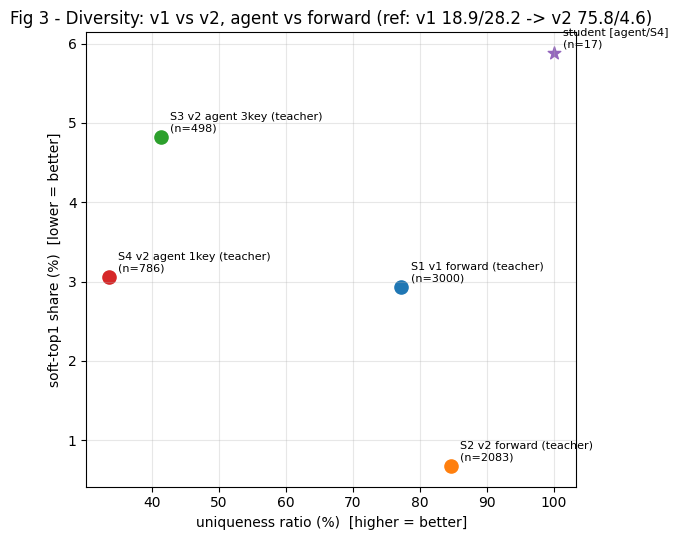

In [23]:
# ── Fig 3. 다양성 산점 — 고유율 vs soft-top1 (v1/v2 × agent/forward 데이터 + student) ──
import matplotlib.pyplot as plt
import json, os, re
from collections import Counter

_softkey40 = lambda t: re.sub(r"[^a-z0-9 ]", "", (t or "").lower())[:40]
def _diversity(texts):
    ts = [t.strip().lower() for t in texts if t and str(t).strip().lower() != "null"]
    n = len(ts)
    if n < 5: return None
    uniq = len(set(ts)) / n
    soft = Counter(_softkey40(t) for t in ts).most_common(1)[0][1] / n
    return uniq, soft, n

_base = os.path.dirname(TRAINING_JSONL_PATH)
CANDS = [  # (라벨, 파일 stem, 자유출력 key)
    ("S1 v1 forward",      "training_data_forward_s1", "reasoning"),
    ("S2 v2 forward",      "training_data_forward",    "reasoning"),
    ("S3 v2 agent 3key",   "training_data_mined_3key", "what_missing"),
    ("S4 v2 agent 1key",   "training_data_mined",      "what_missing"),
]
pts = []
for lab, stem, key in CANDS:
    p = os.path.join(_base, f"{stem}.jsonl")
    if not os.path.exists(p):
        print(f"⏭ 없음: {stem}.jsonl (해당 stage 미생성)"); continue
    texts = []
    for line in open(p, encoding="utf-8"):
        if not line.strip(): continue
        try: texts.append(json.loads(json.loads(line)["assistant"]).get(key))
        except Exception: pass
    d = _diversity(texts)
    if d: pts.append((lab + " (teacher)",) + d)

# student(Block 0) 점 — 현재 stage 모델의 실제 출력 다양성
_st = _diversity([r.get("text") for r in block0_rows if r.get("parse_ok")])
if _st: pts.append((f"student [{mode}/{EXPERIMENT_STAGE}]",) + _st)

if pts:
    plt.figure(figsize=(6.5, 5.5))
    for lab, u, s, n in pts:
        is_student = lab.startswith("student")
        plt.scatter(u * 100, s * 100, s=90, marker="*" if is_student else "o")
        plt.annotate(f"{lab}\n(n={n})", (u * 100, s * 100),
                     textcoords="offset points", xytext=(7, 4), fontsize=8)
    plt.xlabel("uniqueness ratio (%)  [higher = better]")
    plt.ylabel("soft-top1 share (%)  [lower = better]")
    plt.title("Fig 3 - Diversity: v1 vs v2, agent vs forward (ref: v1 18.9/28.2 -> v2 75.8/4.6)")
    plt.grid(alpha=.3); plt.tight_layout(); plt.show()
else:
    print("⚠ 표시할 데이터 없음 — NB01-04(v3)로 stage별 jsonl 생성 필요")

In [ ]:
# ============================================================
# [Section 2.5 — 4번째 블록] 평가 결과 일괄 저장
#   Section 1 ~ 2.5 산출물을 gs://fraud_ecomm/evaluation/{run_tag}/ 에 아카이브
#   run_tag = {STAGE}_{MODEL_TAG}{METHOD}_{CASE}_{날짜} — s1~s4 / sft·grpo 런별 분리
# ============================================================
import json, os, shutil, datetime
import numpy as np
from collections import Counter

EVAL_ROOT = "/content/gcs_mount/evaluation"        # = gs://fraud_ecomm/evaluation (버킷 마운트)
run_tag = (f"{EXPERIMENT_STAGE}_{MODEL_TAG}{METHOD_SUFFIX}"
           f"_{globals().get('EXPERIMENT_CASE', 'case')}_{datetime.date.today():%m%d}")
EVAL_DIR = os.path.join(EVAL_ROOT, run_tag)
os.makedirs(EVAL_DIR, exist_ok=True)
print(f"📦 저장 위치: {EVAL_DIR}")

# ── (1) 실행 메타: 검증한 데이터/모델 정보 ──
_summary = {
    "run_tag": run_tag, "date": str(datetime.date.today()),
    "experiment_stage": EXPERIMENT_STAGE, "mode": mode, "train_mode": TRAIN_MODE,
    "use_grpo": USE_GRPO, "method": METHOD_SUFFIX, "use_gguf": USE_GGUF,
    "base_model": BASE_MODEL_ID, "adapter_gcs": ADAPTER_GCS,
    "train_jsonl": TRAINING_JSONL_PATH, "eval_jsonl": EVAL_JSONL_PATH,
    "n_train": len(training_records), "n_eval": len(eval_recs),
    "gen_max_new": GEN_MAX_NEW,
}

# ── (2) Section 1 핵심 지표: block0_rows에서 재계산 (P4/P5/conf) ──
_ok = [r for r in block0_rows if r.get("parse_ok")]
_summary["block0"] = {"n": len(block0_rows), "parse_ok": len(_ok)}
_texts = [r["text"].strip().lower() for r in _ok if r.get("text") and r["text"] != "null"]
if _texts:
    _c  = Counter(_texts)
    _ck = Counter(__import__("re").sub(r"[^a-z0-9 ]", "", t)[:40] for t in _texts)
    _summary["block0"].update({
        "p4_uniqueness": round(len(_c) / len(_texts), 4),
        "p4_top1":       round(_c.most_common(1)[0][1] / len(_texts), 4),
        "p4_soft_top1":  round(_ck.most_common(1)[0][1] / len(_texts), 4)})
_cls_rows = [r for r in _ok if r.get("cls") in ("NORMAL", "ABNORMAL")]
if _cls_rows:
    _y  = [int(r["rec"]["metadata"]["gt_label"]) for r in _cls_rows]
    _yp = [int(r["cls"] == "ABNORMAL") for r in _cls_rows]
    _tp = sum(a and b for a, b in zip(_y, _yp)); _fn = sum(a and not b for a, b in zip(_y, _yp))
    _summary["block0"].update({
        "p5_cls_acc": round(float(np.mean([a == b for a, b in zip(_y, _yp)])), 4),
        "p5_fnr":     round(_fn / max(_tp + _fn, 1), 4)})
_confs = [r["conf"] for r in _ok if r.get("conf") is not None]
if _confs:
    _summary["block0"].update({"conf_mean": round(float(np.mean(_confs)), 2),
                               "conf_std":  round(float(np.std(_confs)), 2)})

# ── (3) Section 2 judge 결과 (실행된 경우만) ──
if "scored" in dir() and scored:
    _summary["judge"] = {
        "field": globals().get("_FIELD"), "n": len(scored),
        "mean": round(float(np.mean(scored)), 4),
        "dist": {str(k): v for k, v in Counter(scored).items()},
        "gt_corr":      {k: v for k, v in globals().get("_res_a", {}).items() if not k.startswith("_")},
    }

with open(os.path.join(EVAL_DIR, "summary.json"), "w") as f:
    json.dump(_summary, f, ensure_ascii=False, indent=2)

# ── (4) Block 0 per-row 원자료 (재분석용, rec 원문 제외 slim) ──
with open(os.path.join(EVAL_DIR, "block0_rows.jsonl"), "w") as f:
    for r in block0_rows:
        f.write(json.dumps({
            "test_idx": r["rec"]["metadata"].get("test_idx"),
            "gt": r["rec"]["metadata"].get("gt_label"),
            "nd": r["rec"]["metadata"].get("top1_l2_dist_norm"),
            "parse_ok": r.get("parse_ok"), "cls": r.get("cls"),
            "conf": r.get("conf"), "text": r.get("text")}, ensure_ascii=False) + "\n")

# ── (5) gen_stats(Fig 1 원천) 사본 + (6) 그림 ──
_gs = TRAINING_JSONL_PATH.replace(".jsonl", "_gen_stats.json")
if os.path.exists(_gs):
    shutil.copy(_gs, os.path.join(EVAL_DIR, "gen_stats.json"))
if "fig" in dir():                                       # Fig 1 (plotly)
    fig.write_html(os.path.join(EVAL_DIR, "fig1_rejection_funnel.html"))
if "_fig2" in dir():                                     # Fig 2 (matplotlib)
    _fig2.savefig(os.path.join(EVAL_DIR, "fig2_calibration.png"), dpi=150, bbox_inches="tight")
if "_fig3" in dir():                                     # Fig 3
    _fig3.savefig(os.path.join(EVAL_DIR, "fig3_diversity.png"), dpi=150, bbox_inches="tight")

print("✅ 저장 완료:")
for _f in sorted(os.listdir(EVAL_DIR)):
    print(f"   {_f}  ({os.path.getsize(os.path.join(EVAL_DIR, _f))/1024:.1f} KB)")


## Section 3 — Fraudecom Data Intuition (데이터 자체 실험)
구 NB01의 원데이터 실험을 NB01-04 공용 변수(`test_df/labels/test_emb/top5_indices/gt_clusters/
CLUSTER_PERSONAS/compute_l2_distances/normalize_dist`)로 통합 정리. 모델 불필요 — jsonl/임베딩만 사용.
핵심 실측(시나리오1): top5_spread 단독 AUROC 0.403 / persona_dev 0.496 (무신호),
nd→+std(top3) fusion 0.779→**0.857**(Δ+0.077), +persona ALL 0.873(Δ+0.016, 천장 닫힘),
categorical partial corr(nd 통제) ≈0 → **"거리가 유일 신호"**.

In [25]:
# ── [3-1] 단변량 신호 AUROC — top5_spread / persona_dev (무신호 확인) ──
from sklearn.metrics import roc_auc_score
import numpy as np
K = 5
spread, persona_dev = [], []
for i in range(len(test_df)):
    oi = [int(x) for x in top5_indices[i]][:K]
    dd = compute_l2_distances(test_emb[i], oi)            # prompts에서 import됨
    spread.append(float(np.std(dd)))
    p = CLUSTER_PERSONAS.get(int(gt_clusters[i]), {}).get("numeric_stats", {})
    zs = []
    for f in NUMERIC_COLS:
        v = test_df.iloc[i].get(f)
        s = p.get(f)
        if v is not None and s and s.get("std", 0):
            zs.append(abs((v - s["mean"]) / s["std"]))
    persona_dev.append(float(np.mean(zs)) if zs else 0.0)

print("top5_spread AUROC :", round(roc_auc_score(labels, spread), 3))
print("persona_dev AUROC :", round(roc_auc_score(labels, persona_dev), 3))
# reroute AUROC: 각 샘플의 '최근접 타 cluster reference 거리' vs label.
#   cluster centroid 정의가 있어야 함 → 클러스터별 train_emb 평균으로 centroid 구성 후
#   min_{c != assigned} ||emb - centroid_c|| 를 점수로 roc_auc_score(labels, score) 측정.

top5_spread AUROC : 0.403
persona_dev AUROC : 0.496


In [ ]:
# ── [3-2] 경계(0.3~0.5) 구간: distance 외 구조 신호(spread)가 라벨을 가르는가 ──
import numpy as np
# 경계(0.3~0.5) 샘플에서 distance 외 신호가 NORMAL/ABNORMAL을 가르는가?
a = int(len(test_df)*TRAIN_RATIO); b = len(test_df)-int(len(test_df)*EVAL_RATIO)
spread_n, spread_a = [], []        # top1~3 distance 퍼짐
cdist_n, cdist_a = [], []          # 클러스터 중심까지 거리 (있으면)
for i in range(a, b):
    oi = [int(x) for x in top5_indices[i][:3]]
    ds = [normalize_dist(d) for d in compute_l2_distances(test_emb[i], oi)]
    nd1 = ds[0]
    if not (0.3 <= nd1 < 0.5):     # 경계만
        continue
    spread = max(ds) - min(ds)
    (spread_a if labels[i]==1 else spread_n).append(spread)
print(f"경계(0.3~0.5) 샘플: NORMAL {len(spread_n)}, ABNORMAL {len(spread_a)}")
print(f"top1~3 spread: NORMAL mean={np.mean(spread_n):.3f}  ABNORMAL mean={np.mean(spread_a):.3f}")
print(f"  차이 {abs(np.mean(spread_n)-np.mean(spread_a)):.3f} → >0.05면 구조가 신호")

In [ ]:
# ============================================================
# [spread 개선] 재진술(LLM)이 아니라 deterministic fusion 으로 신호 실현
#   1) spread 변형 비교: std(top3) / gap(top2-top1) / cv / ratio  중 boundary 최강
#   2) nd + best_spread 를 코드로 융합(LogReg) → boundary AUROC 이득 측정
#      = "spread는 LLM 재진술이 아니라 게이트에서 nd와 결합할 때 가치가 나온다"
# ============================================================
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import roc_auc_score

K = 3
y = labels.astype(int)
nd   = np.zeros(len(test_df))
v_std= np.zeros(len(test_df))   # std(top-K)
v_gap= np.zeros(len(test_df))   # top2 - top1 (1차 간격)
v_cv = np.zeros(len(test_df))   # std/mean
v_rat= np.zeros(len(test_df))   # top1 / mean(top-K)  (top1이 유독 가까운가)
for i in range(len(test_df)):
    oi = [int(x) for x in top5_indices[i]][:K]
    dd = np.array([d for d in compute_l2_distances(test_emb[i], oi) if np.isfinite(d)])
    nd[i] = normalize_dist(dd[0]) if len(dd) else 0.5
    if len(dd) > 1:
        m = dd.mean()
        v_std[i] = dd.std()
        v_gap[i] = dd[1] - dd[0]
        v_cv[i]  = dd.std() / m if m > 1e-9 else 0.0
        v_rat[i] = dd[0] / m if m > 1e-9 else 1.0

band = (nd >= 0.3) & (nd < 0.5)
yv = y[band]
print(f"[boundary] n={band.sum()}  NORMAL={int((yv==0).sum())}  ABNORMAL={int((yv==1).sum())}")
if len(np.unique(yv)) < 2 or yv.sum() < 5 or (len(yv) - yv.sum()) < 5:
    print("⚠ boundary 양클래스 부족 → fusion 측정 불가 (band 조정 필요)")
    raise SystemExit

def auc(s):
    try: return roc_auc_score(yv, s[band])
    except Exception: return float("nan")

print("\n── (1) spread 변형 단변량 AUROC (boundary) ──")
variants = {"std(top3)": v_std, "gap(top2-top1)": v_gap, "cv": v_cv, "ratio(top1/mean)": v_rat}
for name, v in variants.items():
    print(f"  {name:18s} AUROC={auc(v):.3f}")
best_name = max(variants, key=lambda k: abs(auc(variants[k]) - 0.5))
best = variants[best_name]
print(f"  → 최강 spread 변형: {best_name}")

def cv_auroc(X):
    Xs = StandardScaler().fit_transform(X)
    p = cross_val_predict(LogisticRegression(max_iter=1000, class_weight="balanced"),
                          Xs, yv, cv=5, method="predict_proba")[:, 1]
    return roc_auc_score(yv, p)

print("\n── (2) nd + spread fusion (코드 결합, LLM 아님) ──")
a_nd   = cv_auroc(nd[band].reshape(-1, 1))
a_fuse = cv_auroc(np.column_stack([nd[band], best[band]]))
a_all  = cv_auroc(np.column_stack([nd[band], v_std[band], v_gap[band]]))
print(f"  nd-only            : {a_nd:.3f}")
print(f"  nd + {best_name:14s}: {a_fuse:.3f}  (Δ {a_fuse-a_nd:+.3f})")
print(f"  nd + std + gap     : {a_all:.3f}  (Δ {a_all-a_nd:+.3f})")

print("\n[결론]")
print("  · fusion Δ>0 → spread 가치는 'LLM 재진술'이 아니라 nd와의 코드 결합에서 실현")
print("  · 이 fused score 를 sufficiency 게이트/anomaly score 보정에 쓰면 됨")
print("  · evaluator(LLM)는 spread를 '판단'하지 않음 — 게이트가 계산, LLM은 설명만")

# ── fused score 를 런타임에 노출(게이트에서 사용 가능하도록) ──
SPREAD_BEST = best
FUSED_SCORE = nd + 0.5 * (best - np.nanmean(best))   # 단순 가산 보정(데모용; 계수는 LogReg 권장)
print(f"\n  fused AUROC(boundary, 단순가산): {auc(FUSED_SCORE):.3f}  (참고용)")

In [ ]:
# ============================================================
# [정제 천장 측정] persona feature별 nd-통제 추가신호 + fusion 천장
#   목적: spread/persona 정제로 evaluator(=fused score) 천장을 더 올릴 수 있나?
#   (1) feature별 단변량 boundary AUROC + nd 통제 partial corr
#   (2) nd + std(top3) [기존 천장 0.857] 에 best feature 추가 시 넘는가
#   결론: 천장 넘으면 정제 가치 / 못 넘으면 정제 닫힘 → graph 필요
# ============================================================
import numpy as np
from scipy.stats import spearmanr
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import roc_auc_score

K = 3
y = labels.astype(int)
N = len(test_df)

# ── nd, spread(std top3) ──────────────────────────────────
nd  = np.zeros(N); v_std = np.zeros(N)
for i in range(N):
    oi = [int(x) for x in top5_indices[i]][:K]
    dd = np.array([d for d in compute_l2_distances(test_emb[i], oi) if np.isfinite(d)])
    nd[i] = normalize_dist(dd[0]) if len(dd) else 0.5
    v_std[i] = float(dd.std()) if len(dd) > 1 else 0.0

# ── persona feature별 deviation (numeric=|z|, categorical=mismatch) ──
feat_dev = {f: np.zeros(N) for f in NUMERIC_COLS + CATEGORICAL_COLS}
for i in range(N):
    per = CLUSTER_PERSONAS.get(int(gt_clusters[i]), {}) or {}
    nst, cdist = per.get("numeric_stats", {}), per.get("categorical_dist", {})
    row = test_df.iloc[i]
    for f in NUMERIC_COLS:
        s = nst.get(f)
        feat_dev[f][i] = abs((row.get(f) - s["mean"]) / s["std"]) if (s and s.get("std") and row.get(f) is not None) else 0.0
    for f in CATEGORICAL_COLS:
        d = cdist.get(f)
        if d and row.get(f) is not None:
            feat_dev[f][i] = 0.0 if str(row.get(f)) == str(max(d, key=d.get)) else 1.0

band = (nd >= 0.3) & (nd < 0.5)
yv = y[band]
print(f"[boundary] n={band.sum()}  NORMAL={int((yv==0).sum())}  ABNORMAL={int((yv==1).sum())}")
if len(np.unique(yv)) < 2:
    print("⚠ 단일 클래스 → skip"); raise SystemExit

def auc(s):
    try: return roc_auc_score(yv, s[band])
    except Exception: return float("nan")

def partial(sig):
    z = nd[band]
    rs = sig[band] - np.polyval(np.polyfit(z, sig[band], 1), z)
    ry = yv - np.polyval(np.polyfit(z, yv.astype(float), 1), z)
    if np.std(rs) < 1e-9 or np.std(ry) < 1e-9: return 0.0
    return float(np.corrcoef(rs, ry)[0, 1])

print("\n── (1) feature별 boundary AUROC + nd-통제 partial corr ──")
rows = []
for f in NUMERIC_COLS + CATEGORICAL_COLS:
    a, p = auc(feat_dev[f]), partial(feat_dev[f])
    rows.append((f, a, p))
    print(f"  {f:18s} AUROC={a:.3f}  partial(|·|,label|nd)={p:+.3f}")
# nd 위에 추가신호 있는 feature (|partial|>0.08)
useful = [f for f, a, p in rows if abs(p) > 0.08]
print(f"  → nd 위 추가신호 후보(|partial|>0.08): {useful or '없음'}")

def cv_auroc(X):
    Xs = StandardScaler().fit_transform(X)
    p = cross_val_predict(LogisticRegression(max_iter=1000, class_weight="balanced"),
                          Xs, yv, cv=5, method="predict_proba")[:, 1]
    return roc_auc_score(yv, p)

print("\n── (2) fusion 천장: nd + std(top3) 에 persona 추가 ──")
base = np.column_stack([nd[band], v_std[band]])
a_base = cv_auroc(base)
print(f"  nd + std(top3) [기존 천장]      : {a_base:.3f}")
if useful:
    Xp = np.column_stack([base] + [feat_dev[f][band] for f in useful])
    print(f"  + persona useful {useful} : {cv_auroc(Xp):.3f}  (Δ {cv_auroc(Xp)-a_base:+.3f})")
# 전체 feature 다 넣은 상한(과적합 주의, 참고용)
Xall = np.column_stack([base] + [feat_dev[f][band] for f in NUMERIC_COLS + CATEGORICAL_COLS])
print(f"  + persona ALL features (상한참고): {cv_auroc(Xall):.3f}  (Δ {cv_auroc(Xall)-a_base:+.3f})")

print("\n[판정]")
print("  · useful 비어있고 Δ≈0 → 정제로 천장 못 넘음 → persona/spread 정제 닫힘")
print("    → evaluator 판별 역할 확대는 graph(새 차원)로만 가능")
print("  · Δ>+0.03 → 특정 feature 정제가 천장 상승 → 그 feature를 fusion/입력에 반영")

In [29]:
# ============================================================
# [재검색 진단] reroute(cluster 재매칭)가 '새 정보'인가 '재정렬'인가
#   가설: 같은 임베딩 공간에서 reference cluster만 바꾸는 reroute 는
#         anomaly score의 순위를 보존(=재정렬)할 뿐 새 신호를 안 준다.
#   측정: nd_assigned vs nd_reroute 의 Spearman.  ~1 → 재정렬(새 정보 없음)
#         + label AUROC 가 reroute 로 개선되는지 (개선 없으면 탐지 기여 0)
# ============================================================
import numpy as np
from scipy.stats import spearmanr
from sklearn.metrics import roc_auc_score

# ── 클러스터 centroid: 정상 test 샘플 평균(임베딩 공간) ──
y = labels.astype(int)
uniq = np.unique(gt_clusters)
centroid = {}
for c in uniq:
    m = (gt_clusters == c) & (y == 0)            # 정상 샘플로 reference 정의
    if m.sum() >= 3:
        centroid[int(c)] = test_emb[m].astype(np.float32).mean(0)
cids = np.array(sorted(centroid.keys()))
C    = np.stack([centroid[c] for c in cids])     # (n_cluster, dim)

def l2_to(vec, mat):
    return np.linalg.norm(mat - vec.astype(np.float32), axis=1)

nd_assigned = np.full(len(y), np.nan)
nd_reroute  = np.full(len(y), np.nan)
for i in range(len(y)):
    a = int(gt_clusters[i])
    if a not in centroid:
        continue
    nd_assigned[i] = float(np.linalg.norm(test_emb[i].astype(np.float32) - centroid[a]))
    dists = l2_to(test_emb[i], C)
    dists[cids == a] = np.inf                    # 자기 cluster 제외
    nd_reroute[i] = float(dists.min())           # 최근접 '다른' cluster 거리

ok = ~np.isnan(nd_assigned) & ~np.isnan(nd_reroute)
# boundary 한정(평가 핵심 구간) — top1 nd 백분위 기반 band 재사용
nd_band = (nd_assigned >= np.percentile(nd_assigned[ok], 30)) & \
          (nd_assigned <  np.percentile(nd_assigned[ok], 50))

for tag, mask in [("전체", ok), ("boundary(p30~p50)", ok & nd_band)]:
    m = mask
    if m.sum() < 10 or len(np.unique(y[m])) < 2:
        print(f"[{tag}] n={m.sum()} → skip"); continue
    rho = spearmanr(nd_assigned[m], nd_reroute[m]).correlation
    auc_a = roc_auc_score(y[m], nd_assigned[m])
    auc_r = roc_auc_score(y[m], nd_reroute[m])
    # reroute = min(assigned, other) 를 실제 재검색 후 점수로 가정한 효과
    nd_after = np.minimum(nd_assigned[m], nd_reroute[m])
    auc_after = roc_auc_score(y[m], nd_after)
    print(f"\n[{tag}] n={m.sum()}")
    print(f"  Spearman(nd_assigned, nd_reroute) = {rho:+.3f}   (~1=순위보존=재정렬)")
    print(f"  AUROC  assigned={auc_a:.3f}  reroute={auc_r:.3f}  "
          f"after_reroute(min)={auc_after:.3f}  (Δ {auc_after-auc_a:+.3f})")

print("\n[판정]")
print("  · Spearman 높고 AUROC Δ≈0 → reroute는 frame 재정렬일 뿐 새 정보 없음")
print("    → 재검색은 탐지 score를 못 올린다 (evaluator의 가치는 score 아닌 triage/설명)")
print("  · Spearman 낮고 Δ>0 → reroute가 새 신호 유입 → 재검색이 탐지에 기여 (가설 반증)")


[전체] n=28302
  Spearman(nd_assigned, nd_reroute) = +0.653   (~1=순위보존=재정렬)
  AUROC  assigned=0.815  reroute=0.786  after_reroute(min)=0.836  (Δ +0.022)

[boundary(p30~p50)] n=5660
  Spearman(nd_assigned, nd_reroute) = +0.102   (~1=순위보존=재정렬)
  AUROC  assigned=0.558  reroute=0.639  after_reroute(min)=0.620  (Δ +0.062)

[판정]
  · Spearman 높고 AUROC Δ≈0 → reroute는 frame 재정렬일 뿐 새 정보 없음
    → 재검색은 탐지 score를 못 올린다 (evaluator의 가치는 score 아닌 triage/설명)
  · Spearman 낮고 Δ>0 → reroute가 새 신호 유입 → 재검색이 탐지에 기여 (가설 반증)


### Section 3 요약 (실측 결론)
1. **거리가 유일 판정 신호** — spread/persona/categorical 단독 무신호, nd 통제 시 정보량 ≈0.
2. **spread 가치는 코드 융합에서만** — nd+std(top3) 0.779→0.857 (Δ+0.077 = 물리적 천장).
3. **정제 천장 닫힘** — persona ALL 추가 Δ+0.016. 판별 확대는 새 차원(graph)으로만 가능.
4. **reroute는 재정렬** — Spearman↑·AUROC Δ≈0이면 재검색이 score를 못 올림
   → evaluator의 가치는 판정이 아니라 **선택적 호출(비용 절감)** + 감사 주석(wm).